# KD-IVIG — main analysis

IVIG resistance in Kawasaki disease: model benchmark, SPA threshold sensitivity, and the
downstream feature-selection and interpretation results.

Parts 1–2 recompute from the prepared datasets in `data/prepared/`; Parts 3–7 read the
result tables in `results/notebook/`.  Neither is part of this repository.

**Runtime**: about 13 min on one RTX A6000; the outputs below are from that run.


## 0. Setup

Load the five splits, both feature panels and the shared helpers.


In [1]:
from pathlib import Path
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

warnings.filterwarnings("ignore")

ROOT = Path.cwd()
PREP = ROOT / "data" / "prepared"
RES = ROOT / "results" / "notebook"
FIG = ROOT / "figures" / "notebook"
RES.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

MAN = json.loads((PREP / "manifest.json").read_text())
PANEL_A = MAN["panels"]["a_features"]
PANEL_B = MAN["panels"]["b_features"]

STEMS = {
    "Original": "original_train",
    "SMOTE": "smote_train",
    "Synthetic": "synthetic_train",
    "SPA": "spa_train",
}


def load_split(stem: str):
    a = pd.read_csv(PREP / f"{stem}_panel_a.csv", index_col=0)
    b = pd.read_csv(PREP / f"{stem}_panel_b.csv", index_col=0)
    return {
        "A": (a[PANEL_A].astype(float), a["Label"].astype(int)),
        "B": (b[PANEL_B].astype(float), b["Label"].astype(int)),
    }


DATA = {name: load_split(stem) for name, stem in STEMS.items()}
VAL = load_split("validation")

counts = pd.DataFrame({
    name: {"n": len(split["A"][1]), "resistant": int(split["A"][1].sum())}
    for name, split in DATA.items()
}).T
counts.loc["Validation"] = [len(VAL["A"][1]), int(VAL["A"][1].sum())]
display(counts)


,n,resistant
Original,1356,172
SMOTE,2368,1184
Synthetic,9568,4322
SPA,5993,3307
Validation,587,78


## Part 1 — Figure 2

Seven models × four training sets × two panels, scored on the fixed validation partition.  AUC is
threshold-free; specificity and sensitivity use the Youden threshold.  Random forest uses 10 trees.


In [2]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.svm import SVC
from xgboost import XGBClassifier

SEED = 42
MODEL_ORDER = ["LR", "EN", "SVM", "RF", "XGB", "HGBT", "TabPFN"]
DATASET_ORDER = ["Original", "SMOTE", "Synthetic", "SPA"]

DEVICE = "cuda"
try:
    import torch
    if not torch.cuda.is_available():
        DEVICE = "cpu"
except Exception:
    DEVICE = "cpu"


def make_model(name: str):
    if name == "LR":
        return LogisticRegression(max_iter=500, random_state=SEED)
    if name == "EN":
        return LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=0.5,
                                  max_iter=5000, random_state=SEED)
    if name == "SVM":
        return SVC(probability=True, random_state=SEED)
    if name == "RF":
        return RandomForestClassifier(n_estimators=10, random_state=SEED)
    if name == "XGB":
        return XGBClassifier(random_state=SEED)
    if name == "HGBT":
        return HistGradientBoostingClassifier(random_state=SEED)
    if name == "TabPFN":
        from tabpfn import TabPFNClassifier
        return TabPFNClassifier(device=DEVICE)
    raise ValueError(name)


def youden_threshold(y_true, score):
    fpr, tpr, thresholds = roc_curve(y_true, score)
    return float(thresholds[np.argmax(tpr - fpr)])


def confusion(y_true, score, threshold):
    pred = (score >= threshold).astype(int)
    tp = int(((pred == 1) & (y_true == 1)).sum())
    fn = int(((pred == 0) & (y_true == 1)).sum())
    tn = int(((pred == 0) & (y_true == 0)).sum())
    fp = int(((pred == 1) & (y_true == 0)).sum())
    return {
        "accuracy": (tp + tn) / len(y_true),
        "sensitivity": tp / (tp + fn) if (tp + fn) else np.nan,
        "specificity": tn / (tn + fp) if (tn + fp) else np.nan,
    }


In [3]:
RUN_BENCHMARK = True
BENCH_CSV = RES / "figure2_benchmark.csv"

if RUN_BENCHMARK:
    rows = []
    t0 = time.time()
    for panel in ("A", "B"):
        Xv, yv = VAL[panel]
        for dataset in DATASET_ORDER:
            X, y = DATA[dataset][panel]
            for model_name in MODEL_ORDER:
                t_fit = time.time()
                model = make_model(model_name).fit(X, y)
                score = model.predict_proba(Xv)[:, 1]
                thr = youden_threshold(yv, score)
                m = confusion(yv, score, thr)
                rows.append({
                    "panel": panel, "dataset": dataset, "model": model_name,
                    "n_train": len(y), "n_train_resistant": int(y.sum()),
                    "auc": roc_auc_score(yv, score),
                    "specificity": m["specificity"], "sensitivity": m["sensitivity"],
                    "accuracy": m["accuracy"], "threshold": thr,
                    "seconds": round(time.time() - t_fit, 1),
                })
                print(f"{panel} {dataset:9s} {model_name:6s} "
                      f"AUC={rows[-1]['auc']*100:5.1f} "
                      f"SPE={m['specificity']*100:5.1f} "
                      f"SEN={m['sensitivity']*100:5.1f} "
                      f"({rows[-1]['seconds']}s)", flush=True)
    bench = pd.DataFrame(rows)
    bench.to_csv(BENCH_CSV, index=False)
    print(f"\nwritten: {BENCH_CSV.relative_to(ROOT)}  ({time.time() - t0:.0f}s)")
else:
    bench = pd.read_csv(BENCH_CSV)

display(bench.pivot_table(index=["panel", "dataset"], columns="model",
                          values="auc").round(3))


A Original  LR     AUC= 69.7 SPE= 76.6 SEN= 59.0 (0.1s)


A Original  EN     AUC= 70.0 SPE= 63.7 SEN= 73.1 (4.2s)


A Original  SVM    AUC= 61.6 SPE= 88.4 SEN= 39.7 (0.2s)


A Original  RF     AUC= 65.9 SPE= 83.5 SEN= 43.6 (0.1s)


A Original  XGB    AUC= 73.6 SPE= 61.5 SEN= 80.8 (22.8s)


A Original  HGBT   AUC= 73.1 SPE= 74.1 SEN= 64.1 (1.0s)


... (48 outputs left out)

B SPA       HGBT   AUC= 80.5 SPE= 81.3 SEN= 69.2 (1.2s)


B SPA       TabPFN AUC= 79.4 SPE= 63.9 SEN= 85.9 (4.1s)



written: results/notebook/figure2_benchmark.csv  (450s)


model               EN   HGBT     LR     RF    SVM  TabPFN    XGB
panel dataset                                                    
A     Original   0.700  0.731  0.697  0.659  0.616   0.794  0.736
      SMOTE      0.690  0.754  0.695  0.720  0.657   0.779  0.748
      SPA        0.682  0.802  0.695  0.704  0.658   0.788  0.799
      Synthetic  0.684  0.760  0.691  0.727  0.660   0.747  0.725
B     Original   0.702  0.740  0.691  0.720  0.626   0.795  0.757
      SMOTE      0.693  0.764  0.680  0.717  0.657   0.775  0.760
      SPA        0.689  0.805  0.693  0.723  0.674   0.794  0.805
      Synthetic  0.690  0.764  0.690  0.689  0.673   0.756  0.752

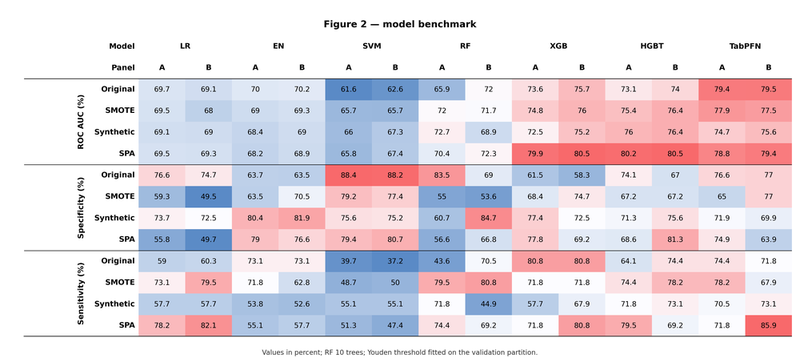

In [4]:
from matplotlib.colors import to_rgb
from matplotlib.patches import Rectangle

BLOCK_SPEC = [("auc", "ROC AUC (%)"),
              ("specificity", "Specificity (%)"),
              ("sensitivity", "Sensitivity (%)")]
BLUE, WHITE, RED = to_rgb("#5A8AC6"), to_rgb("#FCFCFF"), to_rgb("#F8696B")


def heat_colour(v, lo, mid, hi):
    if v <= mid:
        t = 0.0 if mid <= lo else (v - lo) / (mid - lo)
        return tuple(BLUE[i] + t * (WHITE[i] - BLUE[i]) for i in range(3))
    t = 1.0 if hi <= mid else (v - mid) / (hi - mid)
    return tuple(WHITE[i] + t * (RED[i] - WHITE[i]) for i in range(3))


def fmt(v):
    return "" if pd.isna(v) else f"{v:.1f}".removesuffix(".0")


def values_from_bench(bench):
    vals = np.full((3, 4, 2, 7), np.nan)
    for bi, (metric, _) in enumerate(BLOCK_SPEC):
        for si, dataset in enumerate(DATASET_ORDER):
            for pi, panel in enumerate(("A", "B")):
                sub = bench[(bench.panel == panel) & (bench.dataset == dataset)].set_index("model")
                for mi, model in enumerate(MODEL_ORDER):
                    if model in sub.index:
                        vals[bi, si, pi, mi] = 100 * sub.loc[model, metric]
    return vals


def draw_table(values):
    n_blocks, n_sets, n_panels, n_models = values.shape
    CELL_W, CELL_H = 1.0, 0.52
    SPACER_W, LABEL_W = 0.35, 2.45
    HEAD_ROWS = 2
    W = SPACER_W + LABEL_W + CELL_W * n_models * n_panels
    H = CELL_H * (HEAD_ROWS + n_blocks * n_sets)

    fig, ax = plt.subplots(figsize=(13.2, 5.9))
    ax.set_xlim(0, W)
    ax.set_ylim(H, 0)
    ax.axis("off")
    ax.set_facecolor("white")
    x_data0 = SPACER_W + LABEL_W

    ax.text(SPACER_W + LABEL_W - 0.08, CELL_H * 0.5, "Model", ha="right", va="center",
            fontsize=9, fontweight="bold")
    for mi, model in enumerate(MODEL_ORDER):
        xc = x_data0 + (mi * n_panels + n_panels / 2) * CELL_W
        ax.text(xc, CELL_H * 0.5, model, ha="center", va="center", fontsize=9,
                fontweight="bold")
    ax.text(SPACER_W + LABEL_W - 0.08, CELL_H * 1.5, "Panel", ha="right", va="center",
            fontsize=9, fontweight="bold")
    for mi in range(n_models):
        for pi, panel in enumerate(("A", "B")):
            xc = x_data0 + (mi * n_panels + pi + 0.5) * CELL_W
            ax.text(xc, CELL_H * 1.5, panel, ha="center", va="center", fontsize=9,
                    fontweight="bold")

    for bi, (_, metric_label) in enumerate(BLOCK_SPEC):
        block = values[bi].reshape(-1)
        block = block[~np.isnan(block)]
        lo, mid, hi = (float(np.nanmin(block)), float(np.nanpercentile(block, 50)),
                       float(np.nanmax(block)))
        y_block = CELL_H * (HEAD_ROWS + bi * n_sets)
        ax.text(SPACER_W + LABEL_W / 2, y_block + 2 * CELL_H, metric_label,
                ha="center", va="center", rotation=90, fontsize=9, fontweight="bold")
        for si, dataset in enumerate(DATASET_ORDER):
            y = y_block + si * CELL_H
            ax.text(SPACER_W + LABEL_W - 0.08, y + CELL_H / 2, dataset,
                    ha="right", va="center", fontsize=9, fontweight="bold")
            for mi in range(n_models):
                for pi in range(n_panels):
                    v = values[bi, si, pi, mi]
                    x = x_data0 + (mi * n_panels + pi) * CELL_W
                    colour = heat_colour(v, lo, mid, hi) if not pd.isna(v) else "white"
                    ax.add_patch(Rectangle((x, y), CELL_W, CELL_H, facecolor=colour,
                                           edgecolor="none", zorder=1))
                    ax.text(x + CELL_W / 2, y + CELL_H / 2, fmt(v), ha="center",
                            va="center", fontsize=8.5, color="black", zorder=2)
        ax.plot([SPACER_W, W], [y_block, y_block], color="black", lw=0.6, zorder=3)

    ax.plot([SPACER_W, W], [CELL_H * HEAD_ROWS, CELL_H * HEAD_ROWS], color="black",
            lw=0.6, zorder=3)
    ax.plot([SPACER_W, W], [H, H], color="black", lw=1.4, zorder=3)
    ax.set_title("Figure 2 — model benchmark", fontsize=11, fontweight="bold", pad=10)
    fig.text(0.5, 0.005,
             "Values in percent; RF 10 trees; Youden threshold fitted on the validation partition.",
             ha="center", va="bottom", fontsize=8, color="#333333")
    fig.subplots_adjust(left=0.01, right=0.99, top=0.90, bottom=0.06)
    for ext in ("png", "svg"):
        fig.savefig(FIG / f"figure2_benchmark.{ext}", dpi=300, facecolor="white")
    plt.close(fig)


if "bench" not in globals():
    bench = pd.read_csv(BENCH_CSV)
draw_table(values_from_bench(bench))
display(Image(filename=str(FIG / "figure2_benchmark.png"), width=1200))


## Part 2 — SPA sensitivity

Confidence × PCS threshold grid: the synthetic pool is screened at each threshold pair and
SPA-only HGBT is scored on the validation partition, Panels A/B.  The dashed box marks the
plateau region.


In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler

X_ori, y_ori = DATA["Original"]["A"]
X_smote, y_smote = DATA["SMOTE"]["A"]
X_syn, y_syn = DATA["Synthetic"]["A"]

scaler = MinMaxScaler().fit(np.vstack([X_ori, X_smote]))
qc = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1).fit(
    scaler.transform(np.vstack([X_ori, X_smote])),
    np.concatenate([y_ori, y_smote]))
Xsyn_s = scaler.transform(X_syn)
p = qc.predict_proba(Xsyn_s)[:, 1]

rng = np.random.default_rng(20261104)
draws = []
for _ in range(10):
    Xp = Xsyn_s + rng.normal(0, 0.10, size=Xsyn_s.shape)
    draws.append(np.abs(p - qc.predict_proba(Xp)[:, 1]))
pcs = np.median(np.vstack(draws), axis=0)
print(f"QC scores: p median {np.median(p):.3f}; PCS median {np.median(pcs):.3f}")


QC scores: p median 0.343; PCS median 0.292


In [6]:
PCS_GRID = np.round(np.arange(0.00, 0.351, 0.05), 2)
CONF_GRID = np.round(np.arange(0.00, 0.401, 0.05), 2)
rows = []
t0 = time.time()
for conf in CONF_GRID:
    for pcs_thr in PCS_GRID:
        mask = (np.abs(p - 0.5) > conf) & (pcs >= pcs_thr)
        n = int(mask.sum())
        if n < 100:
            continue
        for panel in ("A", "B"):
            Xs, ys = DATA["Synthetic"][panel]
            Xv, yv = VAL[panel]
            model = HistGradientBoostingClassifier(random_state=SEED).fit(
                Xs[mask], ys[mask])
            auc = roc_auc_score(yv, model.predict_proba(Xv)[:, 1])
            rows.append({"confidence": conf, "pcs": pcs_thr, "panel": panel,
                         "n": n, "resistant_pct": 100 * ys[mask].mean(), "auc": auc})
spa = pd.DataFrame(rows)
spa.to_csv(RES / "spa_sensitivity.csv", index=False)
print(f"written: {(RES / 'spa_sensitivity.csv').relative_to(ROOT)}  ({time.time() - t0:.0f}s, {len(spa)} cells)")
display(spa.pivot_table(index="confidence", columns="pcs", values="auc").round(3))


written: results/notebook/spa_sensitivity.csv  (219s, 144 cells)


pcs,0.00,0.05,0.10,0.15,0.20,0.25,0.30,0.35
confidence,,,,,,,,
0.00,0.756,0.756,0.769,0.776,0.778,0.795,0.794,0.768
0.05,0.769,0.784,0.780,0.776,0.777,0.795,0.794,0.768
0.10,0.767,0.772,0.779,0.778,0.782,0.785,0.794,0.768
0.15,0.780,0.776,0.776,0.776,0.780,0.791,0.792,0.768
0.20,0.766,0.770,0.767,0.774,0.789,0.792,0.796,0.767
0.25,0.776,0.776,0.775,0.786,0.793,0.779,0.789,0.783
0.30,0.778,0.778,0.782,0.785,0.795,0.795,0.776,0.768
0.35,0.784,0.784,0.784,0.780,0.781,0.789,0.786,0.763
0.40,0.780,0.780,0.780,0.780,0.782,0.787,0.773,0.734


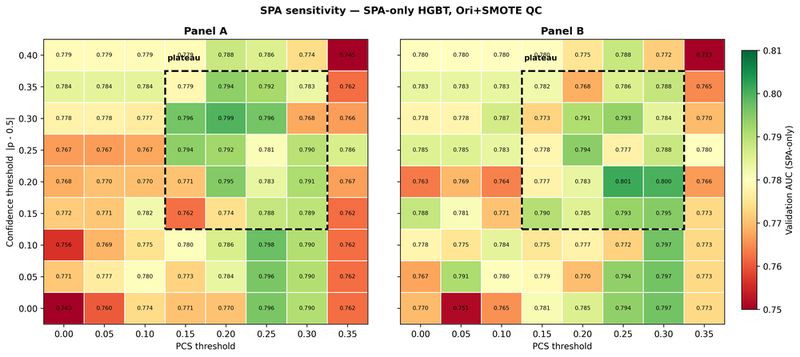

In [7]:
from matplotlib.patches import Rectangle

fig, axes = plt.subplots(1, 2, figsize=(13.8, 6.0), sharey=True)
fig.subplots_adjust(left=0.08, right=0.88, bottom=0.11, top=0.88, wspace=0.10)
edges_x = np.concatenate([[PCS_GRID[0] - 0.025], PCS_GRID + 0.025])
edges_y = np.concatenate([[CONF_GRID[0] - 0.025], CONF_GRID + 0.025])
xx, yy = np.meshgrid(edges_x, edges_y)

for ax, panel in zip(axes, ("A", "B")):
    sub = spa[spa.panel == panel]
    z = sub.pivot(index="confidence", columns="pcs", values="auc").reindex(
        index=CONF_GRID, columns=PCS_GRID).to_numpy()
    mesh = ax.pcolormesh(xx, yy, z, cmap="RdYlGn", vmin=0.75, vmax=0.81,
                         shading="flat", edgecolors="white", linewidth=0.5)
    for i, conf in enumerate(CONF_GRID):
        for j, pcs_thr in enumerate(PCS_GRID):
            if np.isfinite(z[i, j]):
                ax.text(pcs_thr, conf, f"{z[i, j]:.3f}", ha="center", va="center",
                        fontsize=6.5, clip_on=False)
    # Plateau box along cell edges: PCS 0.15-0.30, confidence 0.15-0.35.
    ax.add_patch(Rectangle((0.125, 0.125), 0.20, 0.25, fill=False,
                           edgecolor="black", linewidth=2.2, linestyle="--", zorder=5))
    ax.text(0.128, 0.392, "plateau", fontsize=9, fontweight="bold", zorder=6)
    ax.set_xlim(-0.025, 0.375)
    ax.set_ylim(-0.025, 0.425)
    ax.set_xticks(PCS_GRID)
    ax.set_yticks(CONF_GRID)
    ax.set_xlabel("PCS threshold")
    ax.set_title(f"Panel {panel}", fontweight="bold")
axes[0].set_ylabel("Confidence threshold  |p - 0.5|")
# Dedicated colorbar axes, clear of the right-hand panel and its labels.
cax = fig.add_axes([0.90, 0.15, 0.018, 0.70])
fig.colorbar(mesh, cax=cax, label="Validation AUC (SPA-only)")
fig.suptitle("SPA sensitivity — SPA-only HGBT, Ori+SMOTE QC", fontsize=12,
             fontweight="bold", y=0.97)
for ext in ("png", "svg"):
    fig.savefig(FIG / f"spa_sensitivity.{ext}", dpi=300, facecolor="white",
                bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(FIG / "spa_sensitivity.png"), width=1200))


## Part 3 — Figure 3: nested-CV greedy feature selection

Reads `results/notebook/figure3_*.csv` and prints the 1-SE panel (22 features), the adopted
10-feature panel and the submitted 14-feature comparator.  The 10-feature panel is a parsimony
choice; it is not the CV optimum.


In [8]:
g3 = pd.read_csv(RES / "figure3_greedy_cv.csv")
orig14 = pd.read_csv(RES / "figure3_original14.csv")
g3_meta = json.loads((RES / "figure3_selected_panel.json").read_text())
first10 = g3_meta["full_order"][:10]
print("1-SE selected panel:", g3_meta["selected_n_1se"], "features")
print("First 10:", first10)
display(pd.read_csv(RES / "figure3_panel_comparison.csv").round(3))
display(pd.read_csv(RES / "figure3_first10_overlap.csv"))
display(orig14.round(3))


1-SE selected panel: 22 features
First 10: ['FeverDay', 'IVIGDay', 'LabTestDay', 'TB', 'Na', 'Ca', 'Rash', 'Limbs', 'CRP', 'AST']


,panel,model,cv_mean,cv_sd,val_auc
0,10,LR,0.847,0.007,0.731
1,10,HGBT,0.996,0.002,0.770
2,10,TabPFN,0.998,0.001,0.789
3,14,LR,0.858,0.007,0.736
4,14,HGBT,0.996,0.002,0.772
5,14,TabPFN,0.998,0.001,0.775
6,22,LR,0.866,0.007,0.713
7,22,HGBT,0.996,0.001,0.762
8,22,TabPFN,0.998,0.001,0.771
9,33,LR,0.869,0.007,0.688


,feature,in_first10,in_original14,category
0,ALB,False,True,original14_only
1,AST,True,False,first10_only
2,CRP,True,False,first10_only
3,Ca,True,True,both
4,DigeSys,False,True,original14_only
5,FeverDay,True,True,both
6,IVIGDay,True,True,both
7,LabTestDay,True,True,both
8,Limbs,True,True,both
9,Na,True,True,both


,panel,model,cv_mean,cv_sd,val_auc
0,original14,LR,0.850,0.004,0.739
1,original14,HGBT,0.996,0.001,0.781
2,original14,TabPFN,0.998,0.001,0.801


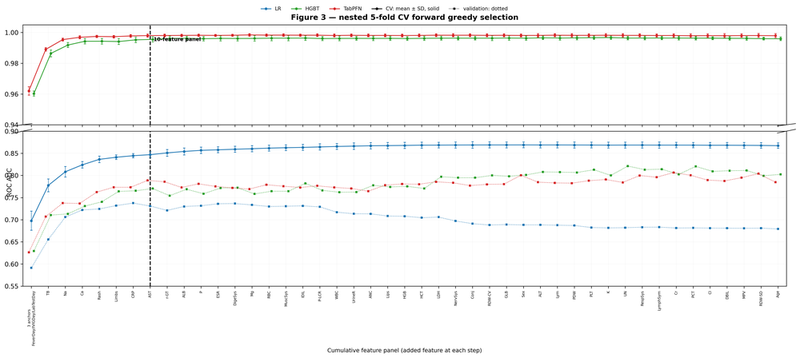

In [9]:
display(Image(filename=str(FIG / "figure3_greedy_cv.png"), width=1100))


## Part 4 — Table 1

Training and validation metrics for HGBT and TabPFN on the four training sets, with 1,000-resample
bootstrap CIs: the revised 10-feature table, and the 14-feature reproduction against the submitted
values.


In [10]:
t10 = pd.read_csv(RES / "table1_10panel.csv")
t14 = pd.read_csv(RES / "table1_14panel.csv")
print("Revised 10-feature Table 1")
display(t10[["training_set", "model", "metric", "train", "val", "ci_low", "ci_high"]].round(1))
print("14-feature reproduction — AUC")
display(t14[t14.metric == "auc"][["training_set", "model", "train", "val", "ci_low", "ci_high"]].round(1))
display(pd.read_csv(RES / "table1_14panel_vs_manuscript.csv")
        .query("metric == 'auc'")[["training_set", "model", "val_rep", "val_ms", "diff_val"]].round(1))


Revised 10-feature Table 1


,training_set,model,metric,train,val,ci_low,ci_high
0,Original,HGBT,auc,100.0,73.0,67.1,78.9
1,Original,HGBT,specificity,99.8,51.7,47.3,55.9
2,Original,HGBT,sensitivity,100.0,84.6,75.9,92.1
3,Original,TabPFN,auc,83.8,77.3,71.7,82.7
4,Original,TabPFN,specificity,74.9,70.3,66.3,74.3
5,Original,TabPFN,sensitivity,79.7,75.6,65.8,85.1
6,SMOTE,HGBT,auc,99.9,74.4,68.7,79.9
7,SMOTE,HGBT,specificity,98.7,62.5,58.1,66.8
8,SMOTE,HGBT,sensitivity,99.4,78.2,68.6,87.0
9,SMOTE,TabPFN,auc,100.0,75.7,70.5,81.0


14-feature reproduction — AUC


,training_set,model,train,val,ci_low,ci_high
0,Original,HGBT,100.0,70.8,64.6,76.7
3,Original,TabPFN,84.7,78.1,72.6,83.1
6,SMOTE,HGBT,100.0,75.2,69.2,80.8
9,SMOTE,TabPFN,100.0,77.4,72.4,82.1
12,Synthetic,HGBT,99.8,74.8,69.0,80.4
15,Synthetic,TabPFN,100.0,77.1,71.3,82.2
18,SPA,HGBT,100.0,78.1,72.8,83.3
21,SPA,TabPFN,100.0,80.1,75.0,84.8


,training_set,model,val_rep,val_ms,diff_val
0,Original,HGBT,70.8,73.0,-2.2
3,Original,TabPFN,78.1,77.3,0.8
6,SMOTE,HGBT,75.7,77.2,-1.5
9,SMOTE,TabPFN,76.6,74.4,2.2
12,Synthetic,HGBT,74.8,75.3,-0.5
15,Synthetic,TabPFN,77.1,74.5,2.6
18,SPA,HGBT,78.1,78.0,0.1
21,SPA,TabPFN,80.1,80.2,-0.1


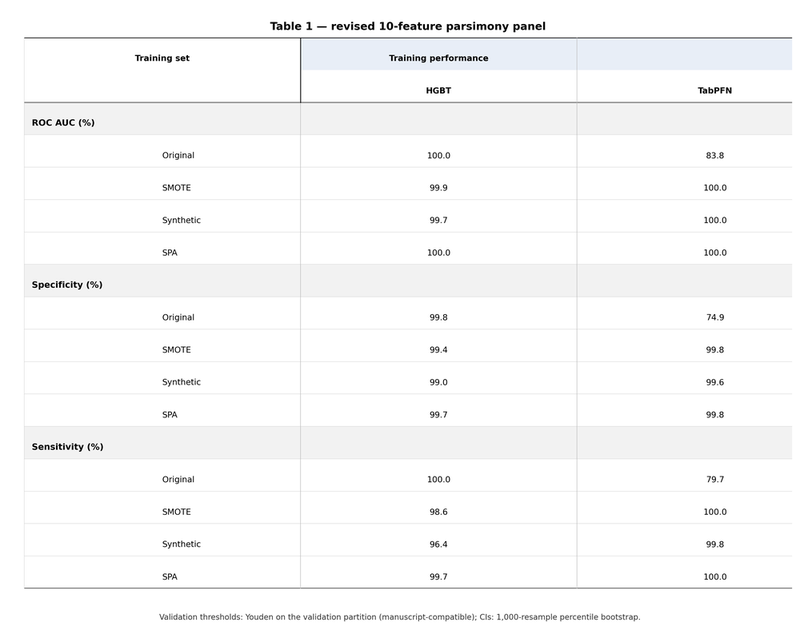

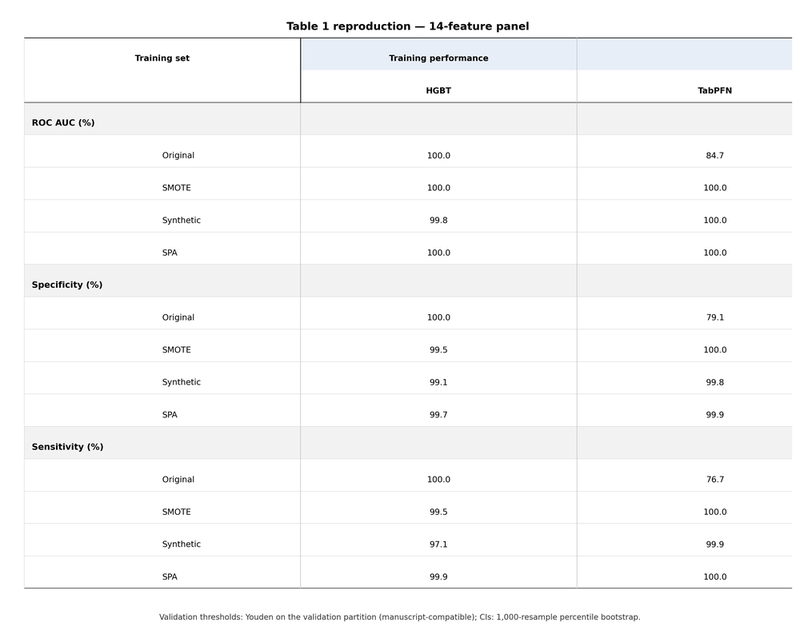

In [11]:
display(Image(filename=str(FIG / "table1_10panel.png"), width=1100))
display(Image(filename=str(FIG / "table1_14panel.png"), width=1100))


## Part 5 — Figure 4

Stitched SHAP interaction heatmap: upper triangle Original, lower triangle SPA, both scaled by the
same maximum absolute value.


,feature_1,feature_2,original,spa,abs_spa,abs_original
0,FeverDay,IVIGDay,-0.409,-1.000,1.000,0.409
1,FeverDay,LabTestDay,0.176,0.690,0.690,0.176
2,IVIGDay,TB,0.114,0.499,0.499,0.114
3,IVIGDay,Na,0.025,0.424,0.424,0.025
4,TB,AST,0.179,0.421,0.421,0.179
5,TB,Na,-0.059,0.312,0.312,0.059
6,FeverDay,CRP,-0.111,0.261,0.261,0.111
7,Na,Ca,0.366,0.251,0.251,0.366
8,FeverDay,Rash,-0.018,0.233,0.233,0.018
9,IVIGDay,AST,0.051,0.211,0.211,0.051


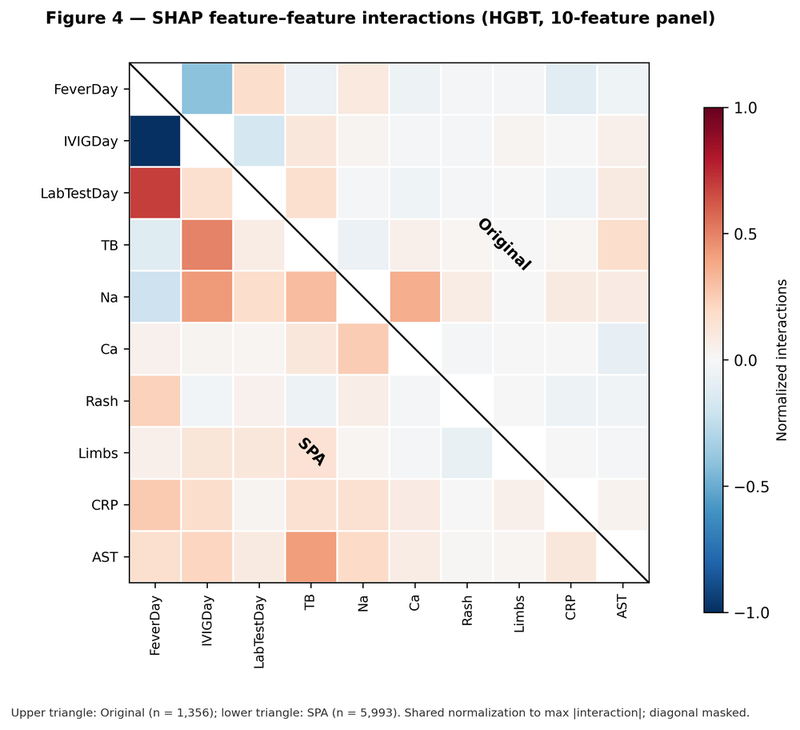

In [12]:
fig4 = pd.read_csv(RES / "figure4_top_pairs.csv")
display(fig4.head(12).round(3))
display(Image(filename=str(FIG / "figure4_shap_interactions.png"), width=1200))


## Part 6 — Figure 5

2D partial dependence for the six strongest SPA interactions on a 16×16 grid.  FeverDay–IVIGDay
is masked to the admissible region (IVIGDay ≥ FeverDay).


,feature_1,feature_2,spa,original
0,FeverDay,IVIGDay,-1.000,-0.409
1,FeverDay,LabTestDay,0.690,0.176
2,IVIGDay,TB,0.499,0.114
3,IVIGDay,Na,0.424,0.025
4,TB,AST,0.421,0.179
5,TB,Na,0.312,-0.059


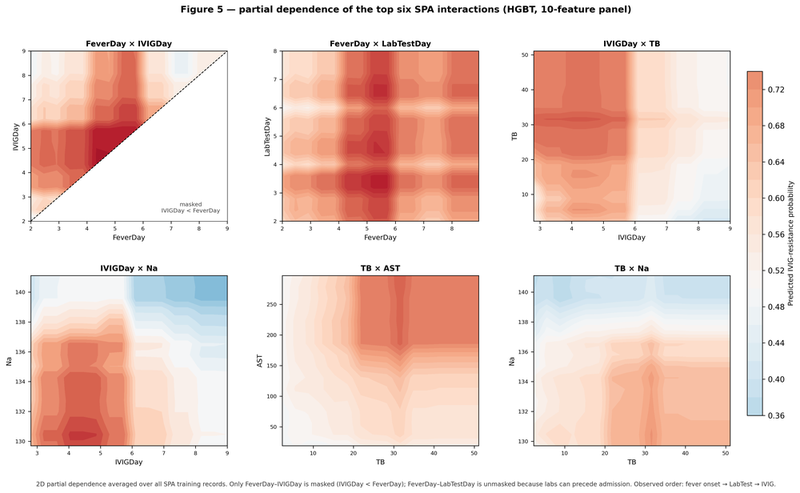

In [13]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
RES = ROOT / 'results' / 'notebook'
FIG = ROOT / 'figures' / 'notebook'
top6 = pd.read_csv(RES / 'figure4_top_pairs.csv').head(6)
display(top6[['feature_1', 'feature_2', 'spa', 'original']].round(3))
display(Image(filename=str(FIG / 'figure5_pdp.png'), width=1200))

## Part 7 — Table 2

Descriptive extreme-score table: top/bottom 1% score groups in the SPA training set and in the
empirical cohort (n=1,943), medians (Q1, Q3) for continuous variables, p values labelled
descriptive.


,feature,unit,spa_low,spa_high,spa_p,emp_low,emp_high,emp_p
0,FeverDay,day,"5.0 (5.0, 6.0)","4.4 (4.4, 5.3)",0.000,"5.0 (5.0, 6.0)","5.0 (3.0, 9.5)",0.466
1,IVIGDay,day,"6.0 (5.0, 6.0)","5.2 (4.3, 5.2)",0.000,"6.0 (6.0, 7.0)","4.0 (3.0, 5.0)",0.004
2,LabTestDay,day,"5.0 (4.0, 6.0)","4.4 (3.5, 4.4)",0.000,"5.0 (4.5, 6.0)","5.0 (2.0, 5.5)",0.180
3,TB,μmol/L,"4.8 (3.8, 5.8)","7.0 (6.3, 23.7)",0.000,"4.8 (3.7, 6.7)","22.2 (7.0, 38.5)",0.000
4,Na,mmol/L,"139.0 (137.5, 140.3)","135.3 (134.2, 136.5)",0.000,"138.0 (136.6, 139.2)","134.8 (133.8, 136.4)",0.002
5,Ca,mmol/L,"2.4 (2.3, 2.5)","2.2 (2.2, 2.3)",0.000,"2.4 (2.3, 2.4)","2.2 (2.1, 2.3)",0.001
6,Rash,n (%),27 (44.3),61 (100.0),0.000,3 (15.8),19 (100.0),0.000
7,Limbs,n (%),14 (23.0),61 (100.0),0.000,3 (15.8),13 (68.4),0.003
8,CRP,mg/L,"9.0 (4.7, 29.4)","51.8 (45.1, 113.9)",0.000,"15.0 (4.7, 48.3)","89.7 (74.6, 137.7)",0.000
9,AST,U/L,"33.0 (29.0, 39.0)","43.8 (23.6, 87.7)",0.039,"33.0 (27.5, 35.5)","47.0 (28.5, 198.0)",0.029


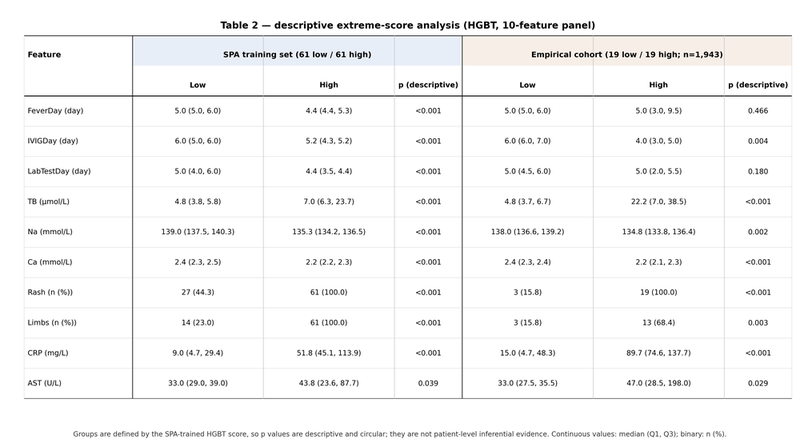

In [14]:
t2 = pd.read_csv(RES / "table2_extreme_scores.csv")
display(t2[["feature", "unit", "spa_low", "spa_high", "spa_p",
            "emp_low", "emp_high", "emp_p"]].round(3))
display(Image(filename=str(FIG / "table2_extreme_scores.png"), width=1200))
